# Process Mining on Bitcoin Mining-Pool Agent Event Logs — Insight-Focused PM4Py Notebook

This notebook implements a stronger process-mining setup for the Bitcoin mining-pool agent event log.

The earlier notebooks mainly discovered the fixed internal decision process:

```text
Observe → Evaluate → Choose → Skip / Mine-Lose / Mine-Win
```

That is valid, but it offers limited insight because the process skeleton is already built into the simulation. This version therefore creates **multiple event-log abstractions** from the same dataset:

1. **Baseline agent-block decision log** — confirms the basic process.
2. **Agent behavioral trace log** — each mining pool is a case; each block outcome is an event.
3. **Block participation-regime log** — the network state per block becomes the process.
4. **Archetype participation-cascade log** — shows which agent groups exit first under unfavorable conditions.
5. **Allocation-intensity decision log** — replaces generic `Choose_Hashrate_Allocation` with low/medium/high allocation activities.
6. **Process cube analysis** — compares behavior across agent type, participation regime, and outcome.

The goal is not just to create more DFGs, but to use process mining to reveal **behavioral persistence, regime shifts, participation collapse, and market-dependent outcomes**.

## 0. Setup

Install requirements if needed:

```bash
pip install pandas numpy matplotlib pm4py graphviz
```

Graph visualization in PM4Py may also require the Graphviz system package. If PM4Py graph export fails, the notebook still produces the tabular process-mining analyses and transition matrices.

In [6]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

OUTPUT_DIR = Path("process_mining_outputs_v4")
OUTPUT_DIR.mkdir(exist_ok=True)

# PM4Py graph rendering can be slow on million-event logs.
# Tables and statistics below always use the full dataset.
# Only graph rendering uses case sampling by default.
USE_SAMPLE_FOR_PM4PY_GRAPHS = True
MAX_CASES_FOR_PM4PY_DFG = 25000
RANDOM_SEED = 42

# Use a relative path by default. If the notebook is run inside this ChatGPT environment,
# the fallback /mnt/data path is also checked.
DATA_PATH = Path("bitcoin_agent_event_log_historical_playthrough_archetypes.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("MAS/bitcoin_agent_event_log_historical_playthrough_archetypes.csv")

print("Data path:", DATA_PATH)
print("Output folder:", OUTPUT_DIR.resolve())

import os
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin' # Adjust the path to Graphviz if needed

Data path: MAS\bitcoin_agent_event_log_historical_playthrough_archetypes.csv
Output folder: C:\Users\mroel\Documents\GitHub\ProcessMiningGroup10\process_mining_outputs_v4


In [7]:
# Optional PM4Py import. The notebook still computes all derived logs and tables if PM4Py is missing.
try:
    import pm4py
    PM4PY_AVAILABLE = True
    print("PM4Py version:", getattr(pm4py, "__version__", "unknown"))
except Exception as e:
    PM4PY_AVAILABLE = False
    print("PM4Py is not available. Install it with: pip install pm4py")
    print("Import error:", e)

PM4Py version: 2.7.22.4


## 1. Load and inspect the event log

Important modeling caveat:

- The original `case_id` is one **agent-block decision case**.
- All events inside a case often share the same timestamp.
- Therefore, activity durations are **not meaningful** unless the simulation explicitly creates event-level times.
- In this notebook, artificial timestamp offsets are used only to preserve event order for PM4Py visualizations. They must not be interpreted as real process time.

In [8]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")
# PM4Py is usually happier with timezone-naive datetimes.
df["timestamp"] = df["timestamp"].dt.tz_convert(None)

df = df.sort_values(["case_id", "event_id"]).reset_index(drop=True)

print("Rows/events:", len(df))
print("Cases:", df["case_id"].nunique())
print("Activities:", df["activity"].nunique())
print("Agents:", df["agent_name"].nunique())
print("Agent types:", df["agent_type"].nunique())
print("Blocks:", int(df["block_height"].nunique()))

display(df.head())
display(df["activity"].value_counts().to_frame("event_count"))

Rows/events: 1124292
Cases: 187200
Activities: 10
Agents: 130
Agent types: 4
Blocks: 1440


,event_id,step,case_id,activity,timestamp,agent_name,agent_type,block_height,btc_price_at_block,transaction_fees_btc,total_reward_btc,block_interval_minutes,network_hashrate_th_s,active,selected_allocation,potential_hashrate_th_s,allocated_hashrate_th_s,power_kw,expected_win_probability_vs_historical_network,expected_revenue_usd,expected_cost_usd,expected_profit_usd,best_allocation_profit_usd,realized_cost_usd,cumulative_profit_usd,reward_btc,realized_revenue_usd
0,1,0,Type 1_001_block_895275,Observe_Market,2025-05-05 00:54:38,Type 1_001,Type 1: Dominant low-cost pools,895275.0,94723.8,0.010113,3.135113,5.183333,8.526674e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,0,Type 1_001_block_895275,Evaluate_Hashrate_Allocation,2025-05-05 00:54:38,Type 1_001,Type 1: Dominant low-cost pools,NaN,NaN,NaN,NaN,NaN,NaN,True,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12544.882546,2513.677484,10031.205062,10031.205062,NaN,NaN,NaN,NaN
2,3,0,Type 1_001_block_895275,Choose_Hashrate_Allocation,2025-05-05 00:54:38,Type 1_001,Type 1: Dominant low-cost pools,NaN,NaN,NaN,NaN,NaN,NaN,True,1.1,NaN,3.601919e+07,819385.789655,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,391,0,Type 1_001_block_895275,Start_Mining,2025-05-05 00:54:38,Type 1_001,Type 1: Dominant low-cost pools,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.1,NaN,3.601919e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,392,0,Type 1_001_block_895275,Consume_Electricity,2025-05-05 00:59:49,Type 1_001,Type 1: Dominant low-cost pools,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2513.677484,NaN,NaN,NaN


,event_count
activity,
Observe_Market,187200
Evaluate_Hashrate_Allocation,187200
Choose_Hashrate_Allocation,187200
Start_Mining,124684
Consume_Electricity,124684
Update_Profit,124684
Lose_Block,123244
Skip_Mining,62516
Win_Block,1440


## 2. Helper functions

These functions create PM4Py-compatible logs, save DFGs, and compute directly-follows transition matrices. The transition matrices are useful because some of the derived logs have long traces where the DFG alone is not enough.

In [9]:
def add_ordered_timestamp(event_df, case_col="case_id", ts_col="timestamp", order_col=None, offset_unit="s"):
    # Add artificial within-case offsets to preserve event order.
    # The offsets are for ordering only, not performance analysis.
    out = event_df.copy()
    if order_col is not None:
        out = out.sort_values([case_col, order_col]).copy()
    else:
        out = out.sort_values([case_col, ts_col]).copy()
    pos = out.groupby(case_col).cumcount()
    out["pm_timestamp"] = out[ts_col] + pd.to_timedelta(pos, unit=offset_unit)
    return out


def transition_pairs(event_df, case_col="case_id", activity_col="activity", order_cols=("timestamp",)):
    # Return directly-follows pairs from an event log.
    ordered = event_df.sort_values([case_col] + list(order_cols)).copy()
    ordered["next_activity"] = ordered.groupby(case_col)[activity_col].shift(-1)
    pairs = ordered.dropna(subset=["next_activity"])[[case_col, activity_col, "next_activity"]].copy()
    return pairs


def transition_matrix(event_df, case_col="case_id", activity_col="activity", order_cols=("timestamp",), normalize=True):
    pairs = transition_pairs(event_df, case_col, activity_col, order_cols)
    mat = pd.crosstab(pairs[activity_col], pairs["next_activity"])
    if normalize:
        mat = mat.div(mat.sum(axis=1).replace(0, np.nan), axis=0)
    return mat.fillna(0)


def plot_matrix(matrix, title, filename=None):
    plt.figure(figsize=(max(7, 0.8 * len(matrix.columns)), max(4, 0.6 * len(matrix.index))))
    plt.imshow(matrix.values)
    plt.xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    plt.yticks(range(len(matrix.index)), matrix.index)
    plt.colorbar(label="Probability" if matrix.max().max() <= 1 else "Count")
    plt.title(title)
    plt.tight_layout()
    if filename:
        path = OUTPUT_DIR / filename
        plt.savefig(path, dpi=150, bbox_inches="tight")
        print("Saved:", path)
    plt.show()



def sample_event_log_by_cases(event_df, case_table=None, case_col="case_id", strata_col=None, max_cases=25000):
    """Sample complete cases for graph rendering while keeping full-case traces intact."""
    if not USE_SAMPLE_FOR_PM4PY_GRAPHS:
        return event_df
    unique_cases = event_df[case_col].drop_duplicates()
    if len(unique_cases) <= max_cases:
        return event_df

    if case_table is not None and strata_col is not None and strata_col in case_table.columns:
        available = case_table[[case_col, strata_col]].drop_duplicates().copy()
        available = available[available[case_col].isin(unique_cases)]
        strata = available[strata_col].dropna().unique()
        per_stratum = max(1, max_cases // max(1, len(strata)))
        sampled_cases = []
        for _, part in available.groupby(strata_col):
            n = min(len(part), per_stratum)
            sampled_cases.extend(part.sample(n=n, random_state=RANDOM_SEED)[case_col].tolist())
        sampled_cases = pd.Index(sampled_cases).drop_duplicates()
        if len(sampled_cases) < max_cases:
            remaining = unique_cases[~unique_cases.isin(sampled_cases)]
            extra_n = min(max_cases - len(sampled_cases), len(remaining))
            extra = pd.Series(remaining).sample(n=extra_n, random_state=RANDOM_SEED).tolist()
            sampled_cases = pd.Index(list(sampled_cases) + extra).drop_duplicates()
    else:
        sampled_cases = pd.Series(unique_cases).sample(n=max_cases, random_state=RANDOM_SEED)

    print(f"Sampling {len(sampled_cases):,} of {len(unique_cases):,} cases for PM4Py graph rendering only.")
    return event_df[event_df[case_col].isin(sampled_cases)].copy()


def save_dfg(event_df, title, filename, case_col="case_id", activity_col="activity", ts_col="pm_timestamp"):
    # Discover and save a frequency DFG using PM4Py. Returns the PM4Py log and DFG if successful.
    if not PM4PY_AVAILABLE:
        print(f"PM4Py not available; skipping DFG: {title}")
        return None, None

    try:
        pm_df = event_df.copy()
        if ts_col not in pm_df.columns:
            pm_df = add_ordered_timestamp(pm_df, case_col=case_col, ts_col="timestamp")
            ts_col = "pm_timestamp"

        formatted = pm4py.format_dataframe(
            pm_df,
            case_id=case_col,
            activity_key=activity_col,
            timestamp_key=ts_col,
        )
        log = pm4py.convert_to_event_log(formatted)
        dfg, start_activities, end_activities = pm4py.discover_dfg(log)
        out_path = OUTPUT_DIR / filename

        try:
            pm4py.save_vis_dfg(dfg, start_activities, end_activities, str(out_path))
        except Exception:
            # Fallback for PM4Py versions where top-level save_vis_dfg is unavailable.
            from pm4py.visualization.dfg import visualizer as dfg_visualizer
            parameters = {dfg_visualizer.Variants.FREQUENCY.value.Parameters.FORMAT: out_path.suffix.replace(".", "")}
            gviz = dfg_visualizer.apply(
                dfg,
                log=log,
                variant=dfg_visualizer.Variants.FREQUENCY,
                parameters=parameters,
            )
            dfg_visualizer.save(gviz, str(out_path))

        print(f"{title}: saved to {out_path}")
        display(Image(filename=str(out_path)))
        return log, dfg
    except Exception as e:
        print(f"Could not create DFG for {title}.")
        print("Error:", e)
        return None, None

## 3. Build a case-level summary

The original event log stores different attributes on different activities. For example:

- market/block attributes are mostly on `Observe_Market`,
- decision variables are mostly on `Evaluate_Hashrate_Allocation` and `Choose_Hashrate_Allocation`,
- realized cost/profit is mostly on `Update_Profit`,
- realized revenue is mostly on `Receive_Reward`.

This section creates one case-level table per **agent-block case**. That table is the basis for the derived event logs.

In [10]:
# Base market/block context from Observe_Market rows
observe_cols = [
    "case_id", "timestamp", "step", "agent_name", "agent_type", "block_height",
    "btc_price_at_block", "transaction_fees_btc", "total_reward_btc",
    "block_interval_minutes", "network_hashrate_th_s"
]
base = df.loc[df["activity"].eq("Observe_Market"), observe_cols].copy()

# Decision context from Evaluate_Hashrate_Allocation rows
eval_cols = [
    "case_id", "active", "selected_allocation", "potential_hashrate_th_s",
    "allocated_hashrate_th_s", "power_kw", "expected_win_probability_vs_historical_network",
    "expected_revenue_usd", "expected_cost_usd", "expected_profit_usd", "best_allocation_profit_usd"
]
decision = df.loc[df["activity"].eq("Evaluate_Hashrate_Allocation"), eval_cols].copy()

# Chosen allocation can also be present on Choose_Hashrate_Allocation rows.
choose_cols = ["case_id", "selected_allocation", "allocated_hashrate_th_s", "power_kw"]
choose = df.loc[df["activity"].eq("Choose_Hashrate_Allocation"), choose_cols].copy()
choose = choose.rename(columns={
    "selected_allocation": "chosen_selected_allocation",
    "allocated_hashrate_th_s": "chosen_allocated_hashrate_th_s",
    "power_kw": "chosen_power_kw",
})

# Realized cost/profit from Update_Profit rows.
update_cols = ["case_id", "realized_cost_usd", "cumulative_profit_usd"]
update = df.loc[df["activity"].eq("Update_Profit"), update_cols].copy()

# Realized revenue from Receive_Reward rows.
reward_cols = ["case_id", "reward_btc", "realized_revenue_usd"]
reward = df.loc[df["activity"].eq("Receive_Reward"), reward_cols].copy()

case_summary = (
    base
    .merge(decision, on="case_id", how="left")
    .merge(choose, on="case_id", how="left")
    .merge(update, on="case_id", how="left")
    .merge(reward, on="case_id", how="left")
)

# Determine outcome based on the activities present in each case.
# This set-based method is much faster than a full case x activity crosstab.
win_cases = set(df.loc[df["activity"].eq("Win_Block"), "case_id"])
lose_cases = set(df.loc[df["activity"].eq("Lose_Block"), "case_id"])
skip_cases = set(df.loc[df["activity"].eq("Skip_Mining"), "case_id"])

case_summary["outcome"] = np.select(
    [
        case_summary["case_id"].isin(win_cases),
        case_summary["case_id"].isin(lose_cases),
        case_summary["case_id"].isin(skip_cases),
    ],
    ["Mine_Win", "Mine_Lose", "Skip"],
    default="Other",
)
case_summary["mined"] = case_summary["outcome"].isin(["Mine_Win", "Mine_Lose"])

# Prefer the evaluated allocation, but fall back to chosen allocation when needed.
case_summary["allocation"] = case_summary["selected_allocation"].fillna(case_summary["chosen_selected_allocation"])
case_summary["realized_cost_usd"] = case_summary["realized_cost_usd"].fillna(0)
case_summary["realized_revenue_usd"] = case_summary["realized_revenue_usd"].fillna(0)
case_summary["realized_profit_usd"] = case_summary["realized_revenue_usd"] - case_summary["realized_cost_usd"]

print("Case summary rows:", len(case_summary))
display(case_summary.head())
display(case_summary["outcome"].value_counts().to_frame("cases"))

Case summary rows: 187200


,case_id,timestamp,step,agent_name,agent_type,block_height,btc_price_at_block,transaction_fees_btc,total_reward_btc,block_interval_minutes,network_hashrate_th_s,active,selected_allocation,potential_hashrate_th_s,allocated_hashrate_th_s,power_kw,expected_win_probability_vs_historical_network,expected_revenue_usd,expected_cost_usd,expected_profit_usd,best_allocation_profit_usd,chosen_selected_allocation,chosen_allocated_hashrate_th_s,chosen_power_kw,realized_cost_usd,cumulative_profit_usd,reward_btc,realized_revenue_usd,outcome,mined,allocation,realized_profit_usd
0,Type 1_001_block_895275,2025-05-05 00:54:38,0,Type 1_001,Type 1: Dominant low-cost pools,895275.0,94723.80,0.010113,3.135113,5.183333,8.526674e+08,True,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12544.882546,2513.677484,10031.205062,10031.205062,1.1,3.601919e+07,819385.789655,0.0,-2513.677484,NaN,0.00000,Mine_Lose,True,1.1,0.00000
1,Type 1_001_block_895276,2025-05-05 00:59:49,1,Type 1_001,Type 1: Dominant low-cost pools,895276.0,94724.11,0.007961,3.132961,3.866667,8.526674e+08,True,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12536.313491,1875.154908,10661.158584,10661.158584,1.1,3.601919e+07,819385.789655,0.0,292378.099579,3.132961,296766.93197,Mine_Win,True,1.1,296766.93197
2,Type 1_001_block_895277,2025-05-05 01:03:41,2,Type 1_001,Type 1: Dominant low-cost pools,895277.0,94724.11,0.002718,3.127718,1.916667,8.526674e+08,True,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12515.334331,929.494890,11585.839441,11585.839441,1.1,3.601919e+07,819385.789655,0.0,291448.604689,NaN,0.00000,Mine_Lose,True,1.1,0.00000
3,Type 1_001_block_895278,2025-05-05 01:05:36,3,Type 1_001,Type 1: Dominant low-cost pools,895278.0,94470.70,0.007818,3.132818,6.700000,8.526674e+08,True,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12502.205494,3249.190831,9253.014663,9253.014663,1.1,3.601919e+07,819385.789655,0.0,288199.413858,NaN,0.00000,Mine_Lose,True,1.1,0.00000
4,Type 1_001_block_895279,2025-05-05 01:12:18,4,Type 1_001,Type 1: Dominant low-cost pools,895279.0,94224.23,0.023774,3.148774,19.766667,8.526674e+08,True,1.1,3.274472e+07,3.601919e+07,819385.789655,0.042243,12533.096175,9585.921209,2947.174967,2947.174967,1.1,3.601919e+07,819385.789655,0.0,278613.492649,NaN,0.00000,Mine_Lose,True,1.1,0.00000


,cases
outcome,
Mine_Lose,123244
Skip,62516
Mine_Win,1440


In [11]:
# Save core derived case table for later inspection.
case_summary.to_csv(OUTPUT_DIR / "case_summary_derived.csv", index=False)
print("Saved:", OUTPUT_DIR / "case_summary_derived.csv")

Saved: process_mining_outputs_v4\case_summary_derived.csv


## 4. Baseline: original agent-block decision process

This is the original process-mining view. It is still useful as a baseline, but it is not the main insight source.

Case notion:

```text
case = one agent deciding for one block
```

Expected process skeleton:

```text
Observe → Evaluate → Choose → Skip
Observe → Evaluate → Choose → Start → Consume → Lose → Update
Observe → Evaluate → Choose → Start → Consume → Win → Receive → Update
```

Sampling 25,000 of 187,200 cases for PM4Py graph rendering only.
Baseline DFG: agent-block decision process: saved to process_mining_outputs_v4\01_baseline_agent_block_dfg.png


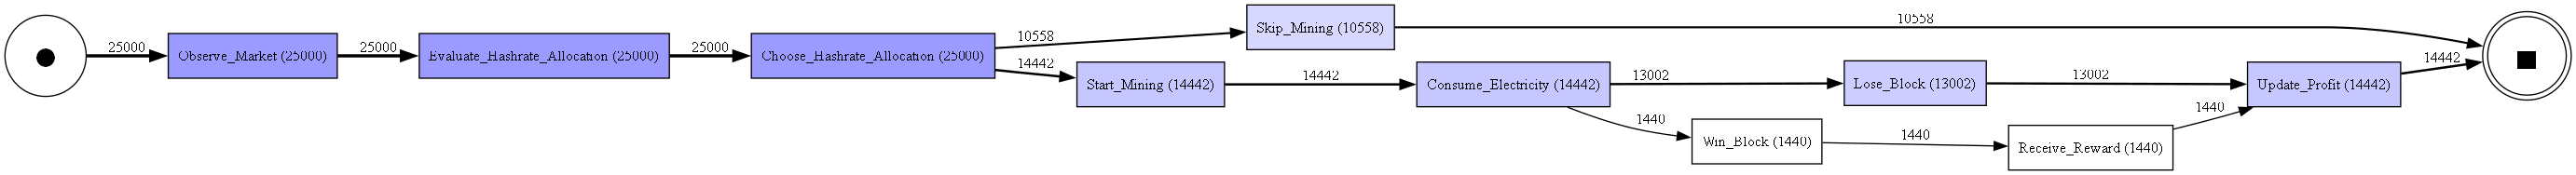

,variant,cases,share
0,Observe_Market → Evaluate_Hashrate_Allocation ...,123244,0.658355
1,Observe_Market → Evaluate_Hashrate_Allocation ...,62516,0.333953
2,Observe_Market → Evaluate_Hashrate_Allocation ...,1440,0.007692


In [12]:
baseline_log = df[["case_id", "activity", "timestamp", "event_id", "agent_name", "agent_type", "block_height"]].copy()
baseline_log = add_ordered_timestamp(baseline_log, case_col="case_id", ts_col="timestamp", order_col="event_id", offset_unit="s")

baseline_log_viz = sample_event_log_by_cases(
    baseline_log,
    case_table=case_summary[["case_id", "outcome"]],
    case_col="case_id",
    strata_col="outcome",
    max_cases=MAX_CASES_FOR_PM4PY_DFG,
)

_ = save_dfg(
    baseline_log_viz,
    title="Baseline DFG: agent-block decision process",
    filename="01_baseline_agent_block_dfg.png",
)

# Variant counts can be derived directly from the outcome because the baseline process has three designed variants.
variant_map = {
    "Skip": "Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Skip_Mining",
    "Mine_Lose": "Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Lose_Block → Update_Profit",
    "Mine_Win": "Observe_Market → Evaluate_Hashrate_Allocation → Choose_Hashrate_Allocation → Start_Mining → Consume_Electricity → Win_Block → Receive_Reward → Update_Profit",
}
variant_table = (
    case_summary["outcome"]
    .map(variant_map)
    .value_counts()
    .reset_index()
)
variant_table.columns = ["variant", "cases"]
variant_table["share"] = variant_table["cases"] / variant_table["cases"].sum()
display(variant_table)
variant_table.to_csv(OUTPUT_DIR / "baseline_variant_table.csv", index=False)


### Interpretation

The baseline DFG should be simple. That is expected. The model tells us that the simulation produces a clean decision protocol, but it does not yet tell us much about behavioral differences.

The next sections therefore change the **case notion** and **activity abstraction**.

# Part A — Agent behavioral trace mining

## 5. Derived log 1: agent behavior over time

Instead of treating one agent-block decision as a case, we now treat each **agent/mining pool** as a case.

Case notion:

```text
case = agent_name
```

Activity notion:

```text
activity = Skip / Mine_Lose / Mine_Win per block
```

This makes process mining answer a different question:

> Do mining pools stay in the same behavioral mode, or do they switch between skipping, losing, and winning over time?

Agent behavior cases: 130
Agent behavior events: 187200


,case_id,agent_type,timestamp,step,block_height,activity,allocation,expected_profit_usd,realized_profit_usd,block_interval_minutes,pm_timestamp
0,Type 1_001,Type 1: Dominant low-cost pools,2025-05-05 00:54:38,0,895275.0,Mine_Lose,1.1,10031.205062,0.00000,5.183333,2025-05-05 00:54:38
1,Type 1_001,Type 1: Dominant low-cost pools,2025-05-05 00:59:49,1,895276.0,Mine_Win,1.1,10661.158584,296766.93197,3.866667,2025-05-05 00:59:49
2,Type 1_001,Type 1: Dominant low-cost pools,2025-05-05 01:03:41,2,895277.0,Mine_Lose,1.1,11585.839441,0.00000,1.916667,2025-05-05 01:03:41
3,Type 1_001,Type 1: Dominant low-cost pools,2025-05-05 01:05:36,3,895278.0,Mine_Lose,1.1,9253.014663,0.00000,6.700000,2025-05-05 01:05:36
4,Type 1_001,Type 1: Dominant low-cost pools,2025-05-05 01:12:18,4,895279.0,Mine_Lose,1.1,2947.174967,0.00000,19.766667,2025-05-05 01:12:18


Agent behavioral DFG: transitions between Skip, Mine_Lose, and Mine_Win: saved to process_mining_outputs_v4\02_agent_behavior_dfg.png


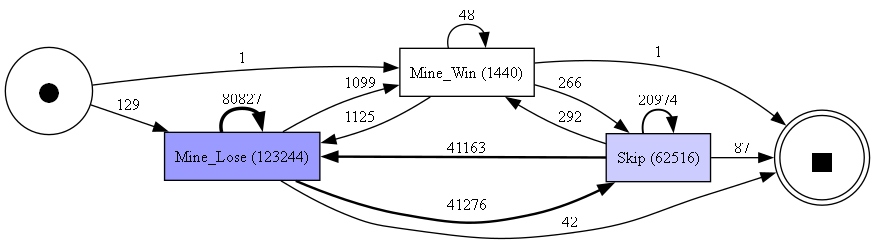

In [13]:
agent_behavior_log = case_summary[[
    "agent_name", "agent_type", "timestamp", "step", "block_height", "outcome",
    "allocation", "expected_profit_usd", "realized_profit_usd", "block_interval_minutes"
]].copy()

agent_behavior_log = agent_behavior_log.rename(columns={
    "agent_name": "case_id",
    "outcome": "activity",
})

# Each agent has one event per block. Order by block step/timestamp.
agent_behavior_log = agent_behavior_log.sort_values(["case_id", "step", "timestamp"]).reset_index(drop=True)
agent_behavior_log["pm_timestamp"] = agent_behavior_log["timestamp"]

print("Agent behavior cases:", agent_behavior_log["case_id"].nunique())
print("Agent behavior events:", len(agent_behavior_log))
display(agent_behavior_log.head())

_ = save_dfg(
    agent_behavior_log,
    title="Agent behavioral DFG: transitions between Skip, Mine_Lose, and Mine_Win",
    filename="02_agent_behavior_dfg.png",
)

next_activity,Mine_Lose,Mine_Win,Skip
activity,,,
Mine_Lose,0.656,0.009,0.335
Mine_Win,0.782,0.033,0.185
Skip,0.659,0.005,0.336


Saved: process_mining_outputs_v4\02_agent_behavior_transition_matrix.png


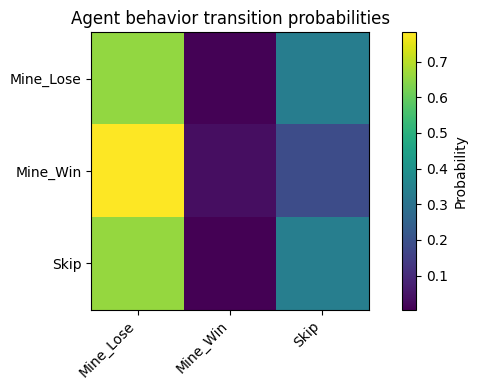

In [14]:
# Overall transition probabilities between behavior states.
agent_transition_matrix = transition_matrix(
    agent_behavior_log,
    case_col="case_id",
    activity_col="activity",
    order_cols=("step",),
    normalize=True,
)

display(agent_transition_matrix.round(3))
plot_matrix(agent_transition_matrix, "Agent behavior transition probabilities", "02_agent_behavior_transition_matrix.png")
agent_transition_matrix.to_csv(OUTPUT_DIR / "agent_behavior_transition_matrix.csv")

In [15]:
# Transition probabilities per agent type.
pairs = transition_pairs(agent_behavior_log, case_col="case_id", activity_col="activity", order_cols=("step",))
agent_type_map = agent_behavior_log[["case_id", "agent_type"]].drop_duplicates()
pairs = pairs.merge(agent_type_map, on="case_id", how="left")

agent_type_transitions = (
    pairs.groupby(["agent_type", "activity", "next_activity"])
    .size()
    .reset_index(name="count")
)
agent_type_transitions["probability"] = (
    agent_type_transitions["count"] /
    agent_type_transitions.groupby(["agent_type", "activity"])["count"].transform("sum")
)

display(agent_type_transitions.sort_values(["agent_type", "activity", "next_activity"]))
agent_type_transitions.to_csv(OUTPUT_DIR / "agent_type_behavior_transition_probabilities.csv", index=False)

,agent_type,activity,next_activity,count,probability
0,Type 1: Dominant low-cost pools,Mine_Lose,Mine_Lose,2207,0.875099
1,Type 1: Dominant low-cost pools,Mine_Lose,Mine_Win,255,0.101110
2,Type 1: Dominant low-cost pools,Mine_Lose,Skip,60,0.023791
3,Type 1: Dominant low-cost pools,Mine_Win,Mine_Lose,254,0.881944
4,Type 1: Dominant low-cost pools,Mine_Win,Mine_Win,27,0.093750
5,Type 1: Dominant low-cost pools,Mine_Win,Skip,7,0.024306
6,Type 1: Dominant low-cost pools,Skip,Mine_Lose,61,0.897059
7,Type 1: Dominant low-cost pools,Skip,Mine_Win,6,0.088235
8,Type 1: Dominant low-cost pools,Skip,Skip,1,0.014706
9,Type 2: Large efficient pools,Mine_Lose,Mine_Lose,10677,0.861118


activity,Mine_Lose,Mine_Win,Skip
agent_type,,,
Type 1: Dominant low-cost pools,0.875,0.094,0.015
Type 2: Large efficient pools,0.861,0.042,0.106
Type 3: Lower/mid-scale pools,0.778,0.003,0.202
Type 4: Small outside-network pools,0.593,0.002,0.356


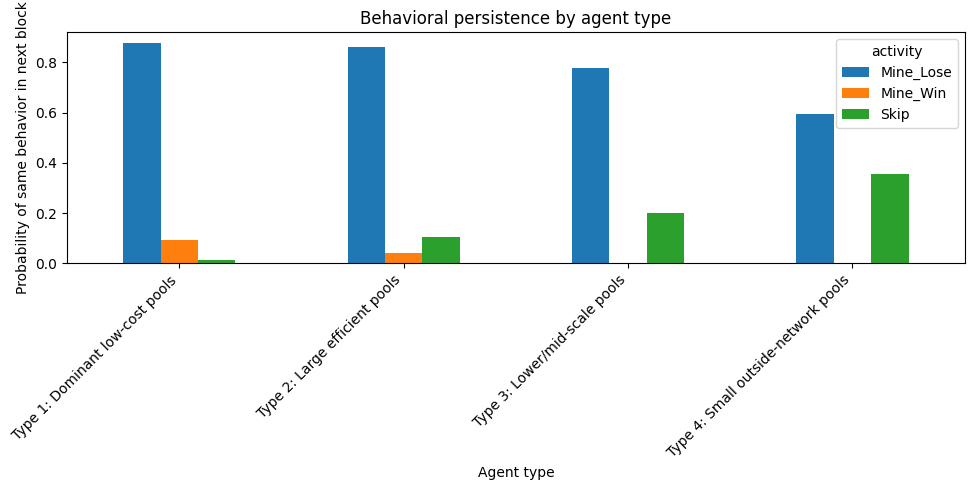

In [16]:
# A compact view: persistence probabilities for each agent type.
persistence = agent_type_transitions[agent_type_transitions["activity"].eq(agent_type_transitions["next_activity"])].copy()
persistence = persistence.pivot(index="agent_type", columns="activity", values="probability").fillna(0)
display(persistence.round(3))

plt.figure(figsize=(10, 5))
persistence.plot(kind="bar", ax=plt.gca())
plt.title("Behavioral persistence by agent type")
plt.ylabel("Probability of same behavior in next block")
plt.xlabel("Agent type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_behavioral_persistence_by_agent_type.png", dpi=150, bbox_inches="tight")
plt.show()

### What to look for

This section can produce a real process-mining insight:

- If `Skip → Skip` is high for Type 4 agents, small/outside-network pools do not only skip more often; they enter a persistent inactive mode.
- If Type 1 has high `Mine_Lose → Mine_Lose`, dominant low-cost pools keep mining even after losing blocks.
- If `Mine_Win → Mine_Lose` dominates, wins are isolated outcomes rather than a stable state.

This is a process-mining view because the insight comes from **directly-follows behavior across time**, not from static averages only.

# Part B — Network participation-regime mining

## 6. Derived log 2: block participation regimes

Now each block is summarized as a network participation state.

Activity examples:

```text
Universal_Mining
High_Participation
Medium_Participation
Low_Participation
Single_Miner
```

This turns the simulation into a market-response process:

> How does the whole mining network move between broad competition and participation collapse?

In [17]:
block_summary = (
    case_summary
    .groupby(["block_height", "step", "timestamp"], as_index=False)
    .agg(
        agents=("case_id", "count"),
        mined_agents=("mined", "sum"),
        skipped_agents=("mined", lambda s: (~s).sum()),
        avg_allocation=("allocation", "mean"),
        avg_expected_profit_usd=("expected_profit_usd", "mean"),
        avg_realized_profit_usd=("realized_profit_usd", "mean"),
        btc_price_at_block=("btc_price_at_block", "first"),
        transaction_fees_btc=("transaction_fees_btc", "first"),
        total_reward_btc=("total_reward_btc", "first"),
        block_interval_minutes=("block_interval_minutes", "first"),
        network_hashrate_th_s=("network_hashrate_th_s", "first"),
    )
)
block_summary["mined_share"] = block_summary["mined_agents"] / block_summary["agents"]

# Participation regimes. Thresholds are intentionally simple and interpretable.
def classify_regime(row):
    mined = row["mined_agents"]
    share = row["mined_share"]
    if mined <= 1:
        return "Single_Miner"
    if share >= 0.95:
        return "Universal_Mining"
    if share >= 0.75:
        return "High_Participation"
    if share >= 0.35:
        return "Medium_Participation"
    return "Low_Participation"

block_summary["participation_regime"] = block_summary.apply(classify_regime, axis=1)

# Add winner type per block.
winners = (
    case_summary[case_summary["outcome"].eq("Mine_Win")]
    [["block_height", "agent_name", "agent_type", "allocation", "realized_revenue_usd"]]
    .rename(columns={
        "agent_name": "winner_agent",
        "agent_type": "winner_agent_type",
        "allocation": "winner_allocation",
        "realized_revenue_usd": "winner_revenue_usd",
    })
)
block_summary = block_summary.merge(winners, on="block_height", how="left")

print("Blocks:", len(block_summary))
display(block_summary.head())
display(block_summary["participation_regime"].value_counts().to_frame("blocks"))
block_summary.to_csv(OUTPUT_DIR / "block_participation_regime_summary.csv", index=False)

Blocks: 1440


,block_height,step,timestamp,agents,mined_agents,skipped_agents,avg_allocation,avg_expected_profit_usd,avg_realized_profit_usd,btc_price_at_block,transaction_fees_btc,total_reward_btc,block_interval_minutes,network_hashrate_th_s,mined_share,participation_regime,winner_agent,winner_agent_type,winner_allocation,winner_revenue_usd
0,895275.0,0,2025-05-05 00:54:38,130,130,0,1.100000,1359.009719,2284.382951,94723.80,0.010113,3.135113,5.183333,8.526674e+08,1.000000,Universal_Mining,Type 4_026,Type 4: Small outside-network pools,1.1,296969.783636
1,895276.0,1,2025-05-05 00:59:49,130,130,0,1.100000,1650.383670,2282.822554,94724.11,0.007961,3.132961,3.866667,8.526674e+08,1.000000,Universal_Mining,Type 1_001,Type 1: Dominant low-cost pools,1.1,296766.931970
2,895277.0,2,2025-05-05 01:03:41,130,130,0,1.100000,2080.251983,2279.002316,94724.11,0.002718,3.127718,1.916667,8.526674e+08,1.000000,Universal_Mining,Type 2_009,Type 2: Large efficient pools,1.1,296270.301039
3,895278.0,3,2025-05-05 01:05:36,130,130,0,1.056923,1014.739992,2276.611596,94470.70,0.007818,3.132818,6.700000,8.526674e+08,1.000000,Universal_Mining,Type 2_006,Type 2: Large efficient pools,1.1,295959.507543
4,895279.0,4,2025-05-05 01:12:18,130,8,122,0.043846,59.347071,2282.236691,94224.23,0.023774,3.148774,19.766667,8.526674e+08,0.061538,Low_Participation,Type 2_007,Type 2: Large efficient pools,1.0,296690.769789


,blocks
participation_regime,
Universal_Mining,793
Low_Participation,410
Medium_Participation,116
Single_Miner,68
High_Participation,53


,block_height,step,timestamp,participation_regime,mined_share,block_interval_minutes,transaction_fees_btc,network_hashrate_th_s,winner_agent_type,case_id,activity,pm_timestamp
0,895275.0,0,2025-05-05 00:54:38,Universal_Mining,1.000000,5.183333,0.010113,8.526674e+08,Type 4: Small outside-network pools,network_playthrough,Universal_Mining,2025-05-05 00:54:38
1,895276.0,1,2025-05-05 00:59:49,Universal_Mining,1.000000,3.866667,0.007961,8.526674e+08,Type 1: Dominant low-cost pools,network_playthrough,Universal_Mining,2025-05-05 00:59:49
2,895277.0,2,2025-05-05 01:03:41,Universal_Mining,1.000000,1.916667,0.002718,8.526674e+08,Type 2: Large efficient pools,network_playthrough,Universal_Mining,2025-05-05 01:03:41
3,895278.0,3,2025-05-05 01:05:36,Universal_Mining,1.000000,6.700000,0.007818,8.526674e+08,Type 2: Large efficient pools,network_playthrough,Universal_Mining,2025-05-05 01:05:36
4,895279.0,4,2025-05-05 01:12:18,Low_Participation,0.061538,19.766667,0.023774,8.526674e+08,Type 2: Large efficient pools,network_playthrough,Low_Participation,2025-05-05 01:12:18


Network regime DFG: transitions between participation regimes: saved to process_mining_outputs_v4\03_network_participation_regime_dfg.png


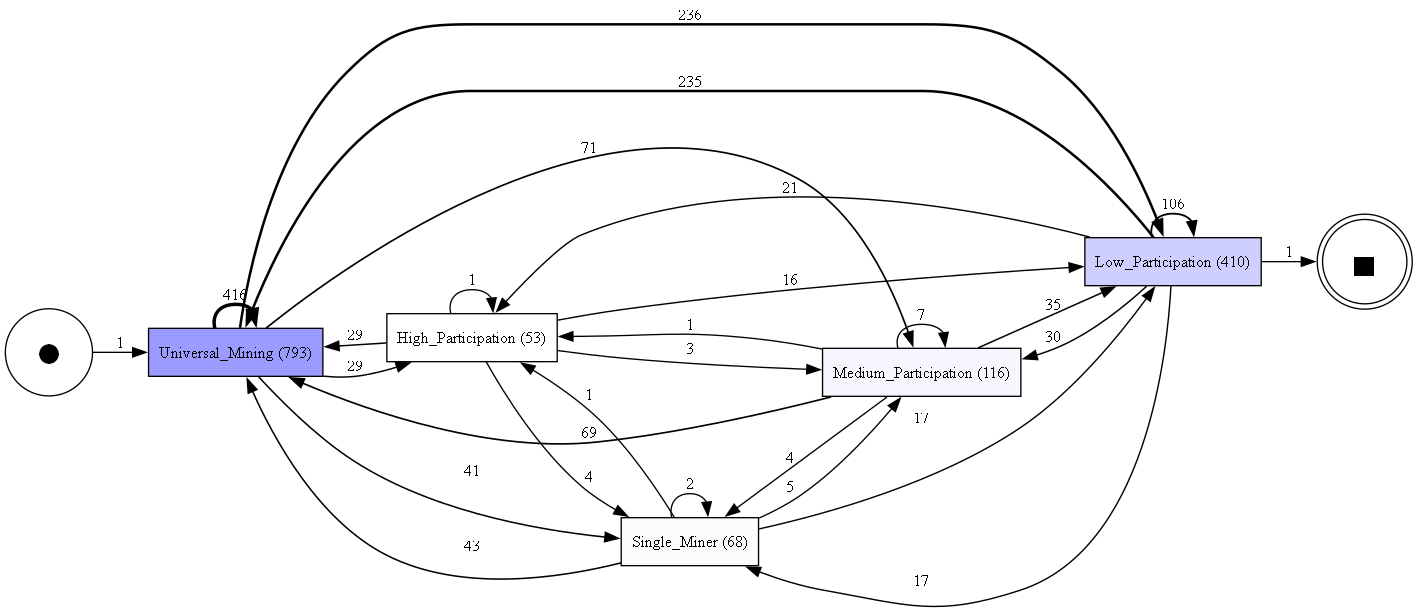

In [18]:
# Build network regime process log. One case over the whole historical playthrough.
regime_log = block_summary[[
    "block_height", "step", "timestamp", "participation_regime", "mined_share",
    "block_interval_minutes", "transaction_fees_btc", "network_hashrate_th_s", "winner_agent_type"
]].copy()
regime_log["case_id"] = "network_playthrough"
regime_log["activity"] = regime_log["participation_regime"]
regime_log = regime_log.sort_values("step")
regime_log["pm_timestamp"] = regime_log["timestamp"]

display(regime_log.head())

_ = save_dfg(
    regime_log,
    title="Network regime DFG: transitions between participation regimes",
    filename="03_network_participation_regime_dfg.png",
)

next_activity,High_Participation,Low_Participation,Medium_Participation,Single_Miner,Universal_Mining
activity,,,,,
High_Participation,0.019,0.302,0.057,0.075,0.547
Low_Participation,0.051,0.259,0.073,0.042,0.575
Medium_Participation,0.009,0.302,0.060,0.034,0.595
Single_Miner,0.015,0.250,0.074,0.029,0.632
Universal_Mining,0.037,0.298,0.090,0.052,0.525


Saved: process_mining_outputs_v4\03_regime_transition_matrix.png


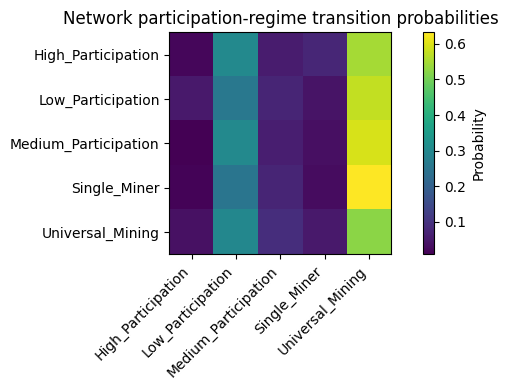

In [19]:
regime_transition_matrix = transition_matrix(
    regime_log,
    case_col="case_id",
    activity_col="activity",
    order_cols=("step",),
    normalize=True,
)

display(regime_transition_matrix.round(3))
plot_matrix(regime_transition_matrix, "Network participation-regime transition probabilities", "03_regime_transition_matrix.png")
regime_transition_matrix.to_csv(OUTPUT_DIR / "network_regime_transition_matrix.csv")

,blocks,avg_mined_share,avg_block_interval_minutes,median_block_interval_minutes,avg_fees_btc,avg_total_reward_btc,avg_network_hashrate_th_s,avg_expected_profit_usd
participation_regime,,,,,,,,
Universal_Mining,793,0.9992,3.3868,3.2167,0.0289,3.1539,8.526674e+08,1928.4012
High_Participation,53,0.8659,8.3956,8.4333,0.0426,3.1676,8.526674e+08,870.1074
Medium_Participation,116,0.5369,9.8514,9.7917,0.0479,3.1729,8.526674e+08,666.0178
Low_Participation,410,0.1417,17.4872,16.3667,0.0627,3.1877,8.526674e+08,231.8641
Single_Miner,68,0.0077,39.2377,36.4750,0.1064,3.2314,8.526674e+08,0.3940


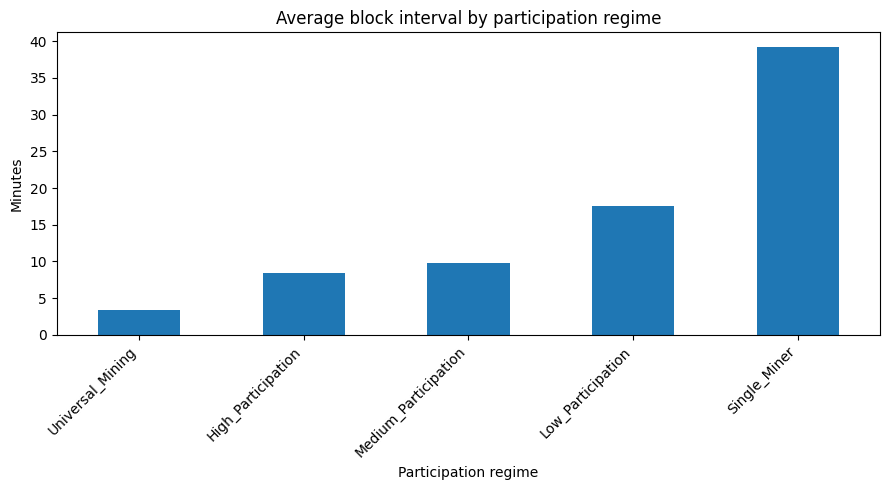

In [20]:
# Link regimes to market/process conditions.
regime_market_summary = (
    block_summary
    .groupby("participation_regime")
    .agg(
        blocks=("block_height", "count"),
        avg_mined_share=("mined_share", "mean"),
        avg_block_interval_minutes=("block_interval_minutes", "mean"),
        median_block_interval_minutes=("block_interval_minutes", "median"),
        avg_fees_btc=("transaction_fees_btc", "mean"),
        avg_total_reward_btc=("total_reward_btc", "mean"),
        avg_network_hashrate_th_s=("network_hashrate_th_s", "mean"),
        avg_expected_profit_usd=("avg_expected_profit_usd", "mean"),
    )
    .sort_values("avg_mined_share", ascending=False)
)

display(regime_market_summary.round(4))
regime_market_summary.to_csv(OUTPUT_DIR / "regime_market_summary.csv")

plt.figure(figsize=(9, 5))
regime_market_summary["avg_block_interval_minutes"].plot(kind="bar")
plt.title("Average block interval by participation regime")
plt.ylabel("Minutes")
plt.xlabel("Participation regime")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_avg_block_interval_by_regime.png", dpi=150, bbox_inches="tight")
plt.show()

winner_agent_type,Type 1: Dominant low-cost pools,Type 2: Large efficient pools,Type 3: Lower/mid-scale pools,Type 4: Small outside-network pools
participation_regime,,,,
High_Participation,9,9,18,17
Low_Participation,142,201,67,0
Medium_Participation,13,48,33,22
Single_Miner,68,0,0,0
Universal_Mining,56,190,180,367


winner_agent_type,Type 1: Dominant low-cost pools,Type 2: Large efficient pools,Type 3: Lower/mid-scale pools,Type 4: Small outside-network pools
participation_regime,,,,
High_Participation,0.170,0.170,0.340,0.321
Low_Participation,0.346,0.490,0.163,0.000
Medium_Participation,0.112,0.414,0.284,0.190
Single_Miner,1.000,0.000,0.000,0.000
Universal_Mining,0.071,0.240,0.227,0.463


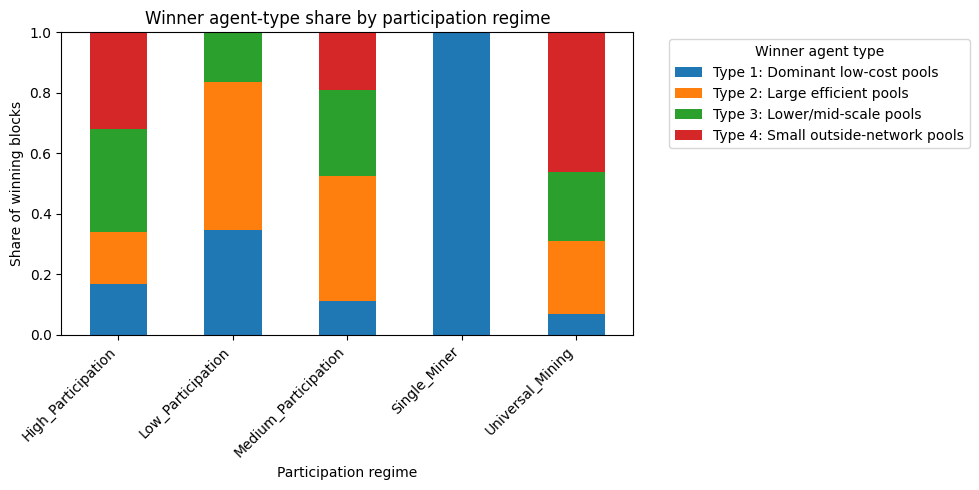

In [21]:
# Winner concentration by regime.
winner_by_regime_counts = pd.crosstab(
    block_summary["participation_regime"],
    block_summary["winner_agent_type"],
    dropna=False,
)
winner_by_regime_share = winner_by_regime_counts.div(winner_by_regime_counts.sum(axis=1), axis=0).fillna(0)

display(winner_by_regime_counts)
display(winner_by_regime_share.round(3))
winner_by_regime_share.to_csv(OUTPUT_DIR / "winner_agent_type_share_by_regime.csv")

plt.figure(figsize=(10, 5))
winner_by_regime_share.plot(kind="bar", stacked=True, ax=plt.gca())
plt.title("Winner agent-type share by participation regime")
plt.ylabel("Share of winning blocks")
plt.xlabel("Participation regime")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Winner agent type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_winner_share_by_regime.png", dpi=150, bbox_inches="tight")
plt.show()

### What to look for

This section can reveal whether the network process has regimes such as:

- broad competition,
- partial participation,
- low participation,
- single-miner dominance.

The important process-mining result is not just the frequency of each regime. It is the **transition behavior**:

> Does the network remain in universal mining, or does it switch into low-participation / single-miner states under unfavorable conditions?

# Part C — Archetype participation-cascade mining

## 7. Derived log 3: archetype participation cascade

This abstraction asks:

> When participation collapses, which archetype exits first?

For each block and each agent type, we classify the group as:

```text
AllMine
Mixed
AllSkip
```

Then each block becomes a short process trace ordered from the most vulnerable group to the most robust group:

```text
Type4_Status → Type3_Status → Type2_Status → Type1_Status
```

This order is analytical, not chronological. It represents a **robustness cascade**, not event time.

,block_height,step,timestamp,agent_type,agent_type_short,agents,mined_agents,avg_expected_profit_usd,avg_allocation,status,activity,cascade_order,case_id,pm_timestamp
3,895275.0,0,2025-05-05 00:54:38,Type 4: Small outside-network pools,Type4,100,100,578.945308,1.1,AllMine,Type4_AllMine,1,block_895275,2025-05-05 00:54:39
2,895275.0,0,2025-05-05 00:54:38,Type 3: Lower/mid-scale pools,Type3,18,18,2378.315920,1.1,AllMine,Type3_AllMine,2,block_895275,2025-05-05 00:54:40
1,895275.0,0,2025-05-05 00:54:38,Type 2: Large efficient pools,Type2,10,10,5593.550878,1.1,AllMine,Type2_AllMine,3,block_895275,2025-05-05 00:54:41
0,895275.0,0,2025-05-05 00:54:38,Type 1: Dominant low-cost pools,Type1,2,2,10015.768714,1.1,AllMine,Type1_AllMine,4,block_895275,2025-05-05 00:54:42
7,895276.0,1,2025-05-05 00:59:49,Type 4: Small outside-network pools,Type4,100,100,824.523276,1.1,AllMine,Type4_AllMine,1,block_895276,2025-05-05 00:59:50
6,895276.0,1,2025-05-05 00:59:49,Type 3: Lower/mid-scale pools,Type3,18,18,2751.436531,1.1,AllMine,Type3_AllMine,2,block_895276,2025-05-05 00:59:51
5,895276.0,1,2025-05-05 00:59:49,Type 2: Large efficient pools,Type2,10,10,6133.166632,1.1,AllMine,Type2_AllMine,3,block_895276,2025-05-05 00:59:52
4,895276.0,1,2025-05-05 00:59:49,Type 1: Dominant low-cost pools,Type1,2,2,10620.012835,1.1,AllMine,Type1_AllMine,4,block_895276,2025-05-05 00:59:53
11,895277.0,2,2025-05-05 01:03:41,Type 4: Small outside-network pools,Type4,100,100,1187.203363,1.1,AllMine,Type4_AllMine,1,block_895277,2025-05-05 01:03:42
10,895277.0,2,2025-05-05 01:03:41,Type 3: Lower/mid-scale pools,Type3,18,18,3301.484230,1.1,AllMine,Type3_AllMine,2,block_895277,2025-05-05 01:03:43


Archetype participation-cascade DFG: saved to process_mining_outputs_v4\04_archetype_participation_cascade_dfg.png


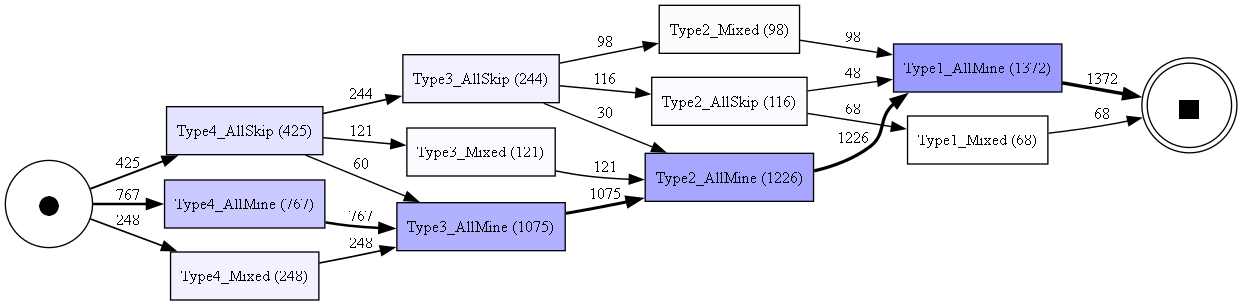

In [22]:
# Helper to create short labels for agent types.
def short_agent_type(label):
    if pd.isna(label):
        return "Unknown"
    if str(label).startswith("Type 1"):
        return "Type1"
    if str(label).startswith("Type 2"):
        return "Type2"
    if str(label).startswith("Type 3"):
        return "Type3"
    if str(label).startswith("Type 4"):
        return "Type4"
    return str(label).split(":")[0].replace(" ", "")

case_summary["agent_type_short"] = case_summary["agent_type"].apply(short_agent_type)

cascade_group = (
    case_summary
    .groupby(["block_height", "step", "timestamp", "agent_type", "agent_type_short"], as_index=False)
    .agg(
        agents=("case_id", "count"),
        mined_agents=("mined", "sum"),
        avg_expected_profit_usd=("expected_profit_usd", "mean"),
        avg_allocation=("allocation", "mean"),
    )
)

def group_status(row):
    if row["mined_agents"] == 0:
        return "AllSkip"
    if row["mined_agents"] == row["agents"]:
        return "AllMine"
    return "Mixed"

cascade_group["status"] = cascade_group.apply(group_status, axis=1)
cascade_group["activity"] = cascade_group["agent_type_short"] + "_" + cascade_group["status"]

# Vulnerability/robustness order: small outside-network pools first, dominant pools last.
type_order = {"Type4": 1, "Type3": 2, "Type2": 3, "Type1": 4}
cascade_group["cascade_order"] = cascade_group["agent_type_short"].map(type_order).fillna(99).astype(int)
cascade_group["case_id"] = "block_" + cascade_group["block_height"].astype(int).astype(str)
cascade_group = cascade_group.sort_values(["case_id", "cascade_order"])
cascade_group["pm_timestamp"] = cascade_group["timestamp"] + pd.to_timedelta(cascade_group["cascade_order"], unit="s")

display(cascade_group.head(12))

_ = save_dfg(
    cascade_group,
    title="Archetype participation-cascade DFG",
    filename="04_archetype_participation_cascade_dfg.png",
)

In [23]:
# Most frequent archetype cascade variants.
cascade_variants = (
    cascade_group.sort_values(["case_id", "cascade_order"])
    .groupby("case_id")["activity"]
    .agg(lambda x: " → ".join(x))
    .value_counts()
    .reset_index()
)
cascade_variants.columns = ["cascade_variant", "blocks"]
cascade_variants["share"] = cascade_variants["blocks"] / cascade_variants["blocks"].sum()

display(cascade_variants.head(15))
cascade_variants.to_csv(OUTPUT_DIR / "archetype_cascade_variants.csv", index=False)

,cascade_variant,blocks,share
0,Type4_AllMine → Type3_AllMine → Type2_AllMine ...,767,0.532639
1,Type4_Mixed → Type3_AllMine → Type2_AllMine → ...,248,0.172222
2,Type4_AllSkip → Type3_Mixed → Type2_AllMine → ...,121,0.084028
3,Type4_AllSkip → Type3_AllSkip → Type2_Mixed → ...,98,0.068056
4,Type4_AllSkip → Type3_AllSkip → Type2_AllSkip ...,68,0.047222
5,Type4_AllSkip → Type3_AllMine → Type2_AllMine ...,60,0.041667
6,Type4_AllSkip → Type3_AllSkip → Type2_AllSkip ...,48,0.033333
7,Type4_AllSkip → Type3_AllSkip → Type2_AllMine ...,30,0.020833


In [24]:
# Link cascade variants to market/block conditions and winner concentration.
block_cascade = (
    cascade_group.sort_values(["case_id", "cascade_order"])
    .groupby("case_id")
    .agg(
        block_height=("block_height", "first"),
        cascade_variant=("activity", lambda x: " → ".join(x)),
    )
    .reset_index()
)

block_cascade = block_cascade.merge(
    block_summary[[
        "block_height", "participation_regime", "mined_share", "block_interval_minutes",
        "transaction_fees_btc", "avg_expected_profit_usd", "winner_agent_type"
    ]],
    on="block_height",
    how="left",
)

cascade_market_summary = (
    block_cascade
    .groupby("cascade_variant")
    .agg(
        blocks=("block_height", "count"),
        avg_mined_share=("mined_share", "mean"),
        avg_block_interval_minutes=("block_interval_minutes", "mean"),
        avg_fees_btc=("transaction_fees_btc", "mean"),
        avg_expected_profit_usd=("avg_expected_profit_usd", "mean"),
    )
    .sort_values("blocks", ascending=False)
)

display(cascade_market_summary.head(15).round(4))
cascade_market_summary.to_csv(OUTPUT_DIR / "cascade_market_summary.csv")

,blocks,avg_mined_share,avg_block_interval_minutes,avg_fees_btc,avg_expected_profit_usd
cascade_variant,,,,,
Type4_AllMine → Type3_AllMine → Type2_AllMine → Type1_AllMine,767,1.0000,3.2365,0.0284,1960.3288
Type4_Mixed → Type3_AllMine → Type2_AllMine → Type1_AllMine,248,0.5972,9.7267,0.0466,709.4721
Type4_AllSkip → Type3_Mixed → Type2_AllMine → Type1_AllMine,121,0.1654,15.4025,0.0517,256.4170
Type4_AllSkip → Type3_AllSkip → Type2_Mixed → Type1_AllMine,98,0.0622,21.3320,0.0730,74.0266
Type4_AllSkip → Type3_AllSkip → Type2_AllSkip → Type1_Mixed,68,0.0077,39.2377,0.1064,0.3940
Type4_AllSkip → Type3_AllMine → Type2_AllMine → Type1_AllMine,60,0.2308,13.0661,0.0531,408.0130
Type4_AllSkip → Type3_AllSkip → Type2_AllSkip → Type1_AllMine,48,0.0154,26.2649,0.0791,18.5893
Type4_AllSkip → Type3_AllSkip → Type2_AllMine → Type1_AllMine,30,0.0923,18.3250,0.0906,149.4906


### What to look for

This section should reveal whether participation decline follows an ordered pattern, for example:

```text
Type4 becomes Mixed or AllSkip first,
then Type3 weakens,
then Type2 weakens,
while Type1 remains active the longest.
```

That is a stronger process-mining insight than simply saying “Type 4 skips more often.” It shows an **archetype exit sequence**.

# Part D — Allocation-intensity process mining

## 8. Derived log 4: replace generic choice with allocation intensity

The original activity `Choose_Hashrate_Allocation` is too generic. It hides the decision intensity.

We replace it with one of:

```text
Choose_Skip
Choose_Low_Allocation
Choose_Medium_Allocation
Choose_High_Allocation
```

This allows PM4Py to show whether low/medium/high allocation choices lead to different paths and outcomes.

In [25]:
# Compute allocation categories. Quantiles are based only on positive allocations.
positive_alloc = case_summary.loc[case_summary["allocation"].fillna(0).gt(0), "allocation"]
q1, q2 = positive_alloc.quantile([1/3, 2/3]) if len(positive_alloc) else (np.nan, np.nan)
print("Allocation thresholds:")
print("q1:", q1, "q2:", q2)

def allocation_activity(row):
    alloc = row["allocation"]
    if row["outcome"] == "Skip" or pd.isna(alloc) or alloc <= 0:
        return "Choose_Skip"
    if alloc <= q1:
        return "Choose_Low_Allocation"
    if alloc <= q2:
        return "Choose_Medium_Allocation"
    return "Choose_High_Allocation"

case_summary["allocation_activity"] = case_summary.apply(allocation_activity, axis=1)

display(case_summary["allocation_activity"].value_counts().to_frame("cases"))

Allocation thresholds:
q1: 1.1 q2: 1.1


,cases
allocation_activity,
Choose_Low_Allocation,124630
Choose_Skip,62570


Sampling 25,000 of 187,200 cases for PM4Py graph rendering only.
Allocation-intensity DFG: saved to process_mining_outputs_v4\05_allocation_intensity_dfg.png


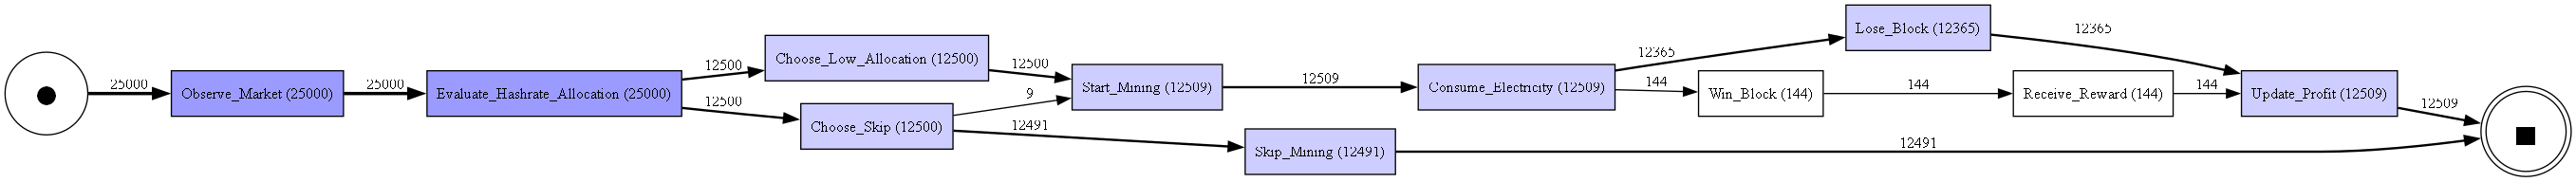

In [26]:
allocation_log = df[["case_id", "activity", "timestamp", "event_id", "agent_name", "agent_type", "block_height"]].copy()
alloc_map = case_summary.set_index("case_id")["allocation_activity"]
allocation_log["activity"] = np.where(
    allocation_log["activity"].eq("Choose_Hashrate_Allocation"),
    allocation_log["case_id"].map(alloc_map),
    allocation_log["activity"],
)
allocation_log = add_ordered_timestamp(
    allocation_log,
    case_col="case_id",
    ts_col="timestamp",
    order_col="event_id",
    offset_unit="s",
)

allocation_log_viz = sample_event_log_by_cases(
    allocation_log,
    case_table=case_summary[["case_id", "allocation_activity"]],
    case_col="case_id",
    strata_col="allocation_activity",
    max_cases=MAX_CASES_FOR_PM4PY_DFG,
)

_ = save_dfg(
    allocation_log_viz,
    title="Allocation-intensity DFG",
    filename="05_allocation_intensity_dfg.png",
)

In [27]:
# Allocation intensity by agent type and outcome.
allocation_outcome_summary = (
    case_summary
    .groupby(["agent_type", "allocation_activity", "outcome"])
    .agg(
        cases=("case_id", "count"),
        avg_expected_profit_usd=("expected_profit_usd", "mean"),
        avg_realized_profit_usd=("realized_profit_usd", "mean"),
        avg_block_interval_minutes=("block_interval_minutes", "mean"),
        avg_fees_btc=("transaction_fees_btc", "mean"),
    )
    .reset_index()
)
allocation_outcome_summary["share_within_agent_type"] = (
    allocation_outcome_summary["cases"] /
    allocation_outcome_summary.groupby("agent_type")["cases"].transform("sum")
)

display(allocation_outcome_summary.sort_values(["agent_type", "allocation_activity", "outcome"]).round(4))
allocation_outcome_summary.to_csv(OUTPUT_DIR / "allocation_outcome_summary_by_agent_type.csv", index=False)

,agent_type,allocation_activity,outcome,cases,avg_expected_profit_usd,avg_realized_profit_usd,avg_block_interval_minutes,avg_fees_btc,share_within_agent_type
0,Type 1: Dominant low-cost pools,Choose_Low_Allocation,Mine_Lose,2524,9723.8932,0.0000,7.7248,0.0396,0.8764
1,Type 1: Dominant low-cost pools,Choose_Low_Allocation,Mine_Win,234,5854.8890,319790.6589,16.3308,0.0623,0.0812
2,Type 1: Dominant low-cost pools,Choose_Skip,Mine_Win,54,0.0000,324480.9354,41.4068,0.1023,0.0188
3,Type 1: Dominant low-cost pools,Choose_Skip,Skip,68,0.0000,0.0000,39.2377,0.1064,0.0236
4,Type 2: Large efficient pools,Choose_Low_Allocation,Mine_Lose,12409,5347.3599,0.0000,7.1508,0.0382,0.8617
5,Type 2: Large efficient pools,Choose_Low_Allocation,Mine_Win,448,4378.7075,319095.1003,10.0501,0.0475,0.0311
6,Type 2: Large efficient pools,Choose_Skip,Skip,1543,0.0000,0.0000,31.0291,0.0916,0.1072
7,Type 3: Lower/mid-scale pools,Choose_Low_Allocation,Mine_Lose,20202,2484.3590,0.0000,5.8098,0.0348,0.7794
8,Type 3: Lower/mid-scale pools,Choose_Low_Allocation,Mine_Win,298,2321.6435,317795.8633,6.5064,0.0329,0.0115
9,Type 3: Lower/mid-scale pools,Choose_Skip,Skip,5420,0.0000,0.0000,24.8520,0.0800,0.2091


outcome,Mine_Lose,Mine_Win,Skip
allocation_activity,,,
Choose_Low_Allocation,0.989,0.011,0.000
Choose_Skip,0.000,0.001,0.999


Saved: process_mining_outputs_v4\05_allocation_outcome_cube.png


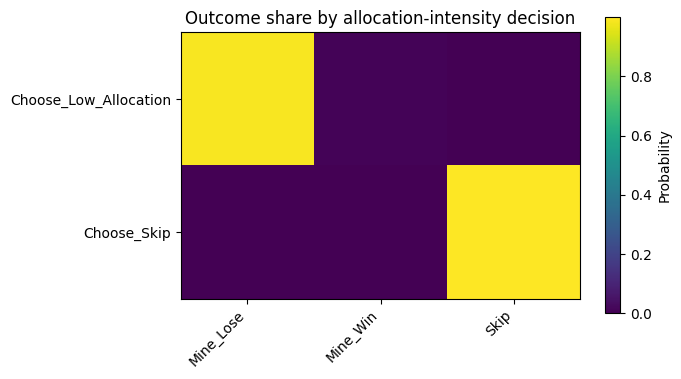

In [28]:
# Compact process cube: allocation activity vs outcome.
alloc_outcome_cube = pd.crosstab(
    case_summary["allocation_activity"],
    case_summary["outcome"],
    normalize="index",
).fillna(0)

display(alloc_outcome_cube.round(3))
plot_matrix(alloc_outcome_cube, "Outcome share by allocation-intensity decision", "05_allocation_outcome_cube.png")
alloc_outcome_cube.to_csv(OUTPUT_DIR / "allocation_outcome_cube.csv")

### What to look for

This section can reveal whether the process branch is not simply:

```text
Choose → Start / Skip
```

but rather:

```text
Choose_Skip → Skip
Choose_Low_Allocation → Start → usually Lose
Choose_High_Allocation → Start → higher exposure and possibly more wins
```

This makes the process model more behaviorally meaningful because the decision activity now contains economic intensity.

# Part E — Process cube analysis

## 9. Combine dimensions: agent type × participation regime × outcome

This section links individual agent decisions to the network regime of the block.

Question examples:

- Do Type 4 agents skip mainly during low-participation regimes?
- Are Type 1 agents still mining in single-miner regimes?
- Does the winner distribution change when participation collapses?

In [29]:
case_cube = case_summary.merge(
    block_summary[["block_height", "participation_regime", "mined_share"]],
    on="block_height",
    how="left",
)

agent_regime_outcome_cube = pd.crosstab(
    [case_cube["agent_type"], case_cube["participation_regime"]],
    case_cube["outcome"],
    normalize="index",
).fillna(0)

display(agent_regime_outcome_cube.round(3))
agent_regime_outcome_cube.to_csv(OUTPUT_DIR / "agent_type_regime_outcome_cube.csv")

outcome                                                   Mine_Lose  Mine_Win   Skip
agent_type                          participation_regime                            
Type 1: Dominant low-cost pools     High_Participation        0.915     0.085  0.000
                                    Low_Participation         0.827     0.173  0.000
                                    Medium_Participation      0.944     0.056  0.000
                                    Single_Miner              0.000     0.500  0.500
                                    Universal_Mining          0.965     0.035  0.000
Type 2: Large efficient pools       High_Participation        0.983     0.017  0.000
                                    Low_Participation         0.740     0.049  0.210
                                    Medium_Participation      0.959     0.041  0.000
                                    Single_Miner              0.000     0.000  1.000
                                    Universal_Mining          0.976     0.024  0.000
Type 3: Lower/mid-scale pools       High_Participation        0.981     0.019  0.000
                                    Low_Participation         0.422     0.009  0.569
                                    Medium_Participation      0.984     0.016  0.000
                                    Single_Miner              0.000     0.000  1.000
                                    Universal_Mining          0.987     0.013  0.000
Type 4: Small outside-network pools High_Participation        0.822     0.003  0.174
                                    Low_Participation         0.008     0.000  0.992
                                    Medium_Participation      0.396     0.002  0.602
                                    Single_Miner              0.000     0.000  1.000
                                    Universal_Mining          0.994     0.005  0.001

In [30]:
# Market context by agent type and outcome.
agent_outcome_market = (
    case_cube
    .groupby(["agent_type", "outcome"])
    .agg(
        cases=("case_id", "count"),
        avg_allocation=("allocation", "mean"),
        avg_block_interval_minutes=("block_interval_minutes", "mean"),
        avg_expected_profit_usd=("expected_profit_usd", "mean"),
        avg_realized_profit_usd=("realized_profit_usd", "mean"),
        avg_transaction_fees_btc=("transaction_fees_btc", "mean"),
        avg_mined_share=("mined_share", "mean"),
    )
    .reset_index()
)

display(agent_outcome_market.round(4))
agent_outcome_market.to_csv(OUTPUT_DIR / "agent_outcome_market_summary.csv", index=False)

,agent_type,outcome,cases,avg_allocation,avg_block_interval_minutes,avg_expected_profit_usd,avg_realized_profit_usd,avg_transaction_fees_btc,avg_mined_share
0,Type 1: Dominant low-cost pools,Mine_Lose,2524,1.0962,7.7248,9723.8932,0.0000,0.0396,0.7273
1,Type 1: Dominant low-cost pools,Mine_Win,288,0.8469,21.0325,4757.0973,320670.0858,0.0698,0.2850
2,Type 1: Dominant low-cost pools,Skip,68,0.0000,39.2377,0.0000,0.0000,0.1064,0.0077
3,Type 2: Large efficient pools,Mine_Lose,12409,1.0789,7.1508,5347.3599,0.0000,0.0382,0.7500
4,Type 2: Large efficient pools,Mine_Win,448,1.0647,10.0501,4378.7075,319095.1003,0.0475,0.5658
5,Type 2: Large efficient pools,Skip,1543,0.0000,31.0291,0.0000,0.0000,0.0916,0.0203
6,Type 3: Lower/mid-scale pools,Mine_Lose,20202,1.0685,5.8098,2484.3590,0.0000,0.0348,0.8268
7,Type 3: Lower/mid-scale pools,Mine_Win,298,1.0688,6.5064,2321.6435,317795.8633,0.0329,0.7676
8,Type 3: Lower/mid-scale pools,Skip,5420,0.0000,24.8520,0.0000,0.0000,0.0800,0.0612
9,Type 4: Small outside-network pools,Mine_Lose,88109,1.0603,3.9827,926.7473,0.0000,0.0305,0.9689


participation_regime,High_Participation,Low_Participation,Medium_Participation,Single_Miner,Universal_Mining
agent_type,,,,,
Type 1: Dominant low-cost pools,0.000,0.000,0.000,0.5,0.000
Type 2: Large efficient pools,0.000,0.210,0.000,1.0,0.000
Type 3: Lower/mid-scale pools,0.000,0.569,0.000,1.0,0.000
Type 4: Small outside-network pools,0.174,0.992,0.602,1.0,0.001


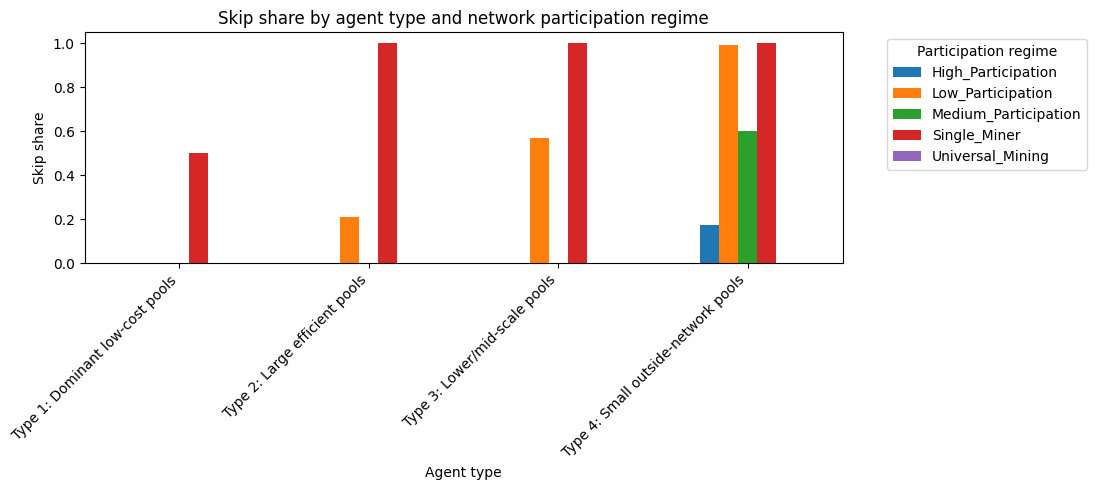

In [31]:
# Example visual: skip share by agent type and participation regime.
skip_share = (
    case_cube.assign(is_skip=case_cube["outcome"].eq("Skip"))
    .groupby(["agent_type", "participation_regime"])["is_skip"]
    .mean()
    .unstack(fill_value=0)
)

display(skip_share.round(3))

plt.figure(figsize=(11, 5))
skip_share.plot(kind="bar", ax=plt.gca())
plt.title("Skip share by agent type and network participation regime")
plt.ylabel("Skip share")
plt.xlabel("Agent type")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Participation regime", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_skip_share_by_agent_type_and_regime.png", dpi=150, bbox_inches="tight")
plt.show()

# Part F — Optional: Petri net / inductive miner on derived logs

A Petri net on the original log is usually not very informative because the process is too simple. It may be more useful to run inductive mining on the **allocation-intensity log**, because it contains richer decision activities.

Saved: process_mining_outputs_v4\07_allocation_intensity_petri_net.png


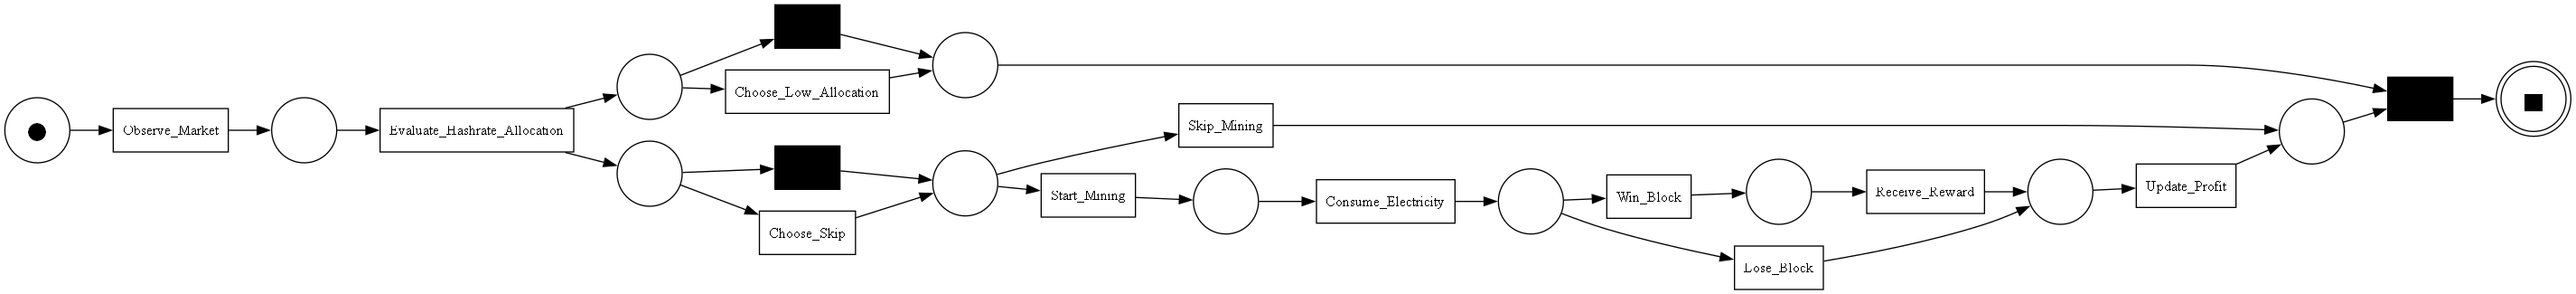

In [32]:
if PM4PY_AVAILABLE:
    try:
        formatted = pm4py.format_dataframe(
            allocation_log_viz,
            case_id="case_id",
            activity_key="activity",
            timestamp_key="pm_timestamp",
        )
        alloc_event_log = pm4py.convert_to_event_log(formatted)
        net, im, fm = pm4py.discover_petri_net_inductive(alloc_event_log)
        petri_path = OUTPUT_DIR / "07_allocation_intensity_petri_net.png"
        pm4py.save_vis_petri_net(net, im, fm, str(petri_path))
        print("Saved:", petri_path)
        display(Image(filename=str(petri_path)))
    except Exception as e:
        print("Could not create Petri net. Error:", e)
else:
    print("PM4Py not available; skipping Petri net.")

# 10. Summary of generated outputs

The notebook writes the most important derived tables and PM4Py graphs to `process_mining_outputs_v4/`.

In [33]:
outputs = sorted(OUTPUT_DIR.glob("*"))
print(f"Generated {len(outputs)} output files:")
for path in outputs:
    print("-", path)

Generated 27 output files:
- process_mining_outputs_v4\01_baseline_agent_block_dfg.png
- process_mining_outputs_v4\02_agent_behavior_dfg.png
- process_mining_outputs_v4\02_agent_behavior_transition_matrix.png
- process_mining_outputs_v4\02_behavioral_persistence_by_agent_type.png
- process_mining_outputs_v4\03_avg_block_interval_by_regime.png
- process_mining_outputs_v4\03_network_participation_regime_dfg.png
- process_mining_outputs_v4\03_regime_transition_matrix.png
- process_mining_outputs_v4\03_winner_share_by_regime.png
- process_mining_outputs_v4\04_archetype_participation_cascade_dfg.png
- process_mining_outputs_v4\05_allocation_intensity_dfg.png
- process_mining_outputs_v4\05_allocation_outcome_cube.png
- process_mining_outputs_v4\06_skip_share_by_agent_type_and_regime.png
- process_mining_outputs_v4\07_allocation_intensity_petri_net.png
- process_mining_outputs_v4\agent_behavior_transition_matrix.csv
- process_mining_outputs_v4\agent_outcome_market_summary.csv
- process_mining

# 11. Suggested interpretation for a report

A defensible interpretation is:

> The original event log is structurally simple because the agent decision protocol is embedded in the simulation. Therefore, classical process discovery mainly confirms the designed control flow. More useful process-mining insights are obtained by changing the case notion and activity abstraction. When each mining pool is treated as a case, process mining reveals behavioral persistence and switching between skip, mine-lose, and mine-win states. When each block is abstracted into a participation regime, process mining reveals transitions between broad competition and participation collapse. The archetype cascade abstraction shows whether weaker/smaller pools exit first, while dominant low-cost pools remain active longer. Finally, replacing the generic allocation-choice activity with allocation-intensity activities links the discovered process paths to economic decision strength and profitability.

In short:

```text
Process mining is not only used to discover the fixed decision skeleton.
It is used to create behavioral views of strategy persistence, network-regime transitions,
archetype exit cascades, and allocation-intensity outcomes.
```